# CONFIG PACKAGE

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sqlalchemy import create_engine

from utils.config import LOOKER_ECOMMERCE
from utils.cleaning import *
from utils.db import *
from utils.stats import *
from utils.visual import *
from utils.outlier import *

# thu muc luu bieu do cho bao cao
FIG_DIR = 'reports/figures'

# KET NOI DATABASE

In [2]:
engine = make_engine(LOOKER_ECOMMERCE)
test_connection(engine)

Connected — MySQL 8.0.46


In [3]:
# Muc chi tiet: 1 dong = 1 mon hang (order_items), join them gia von, san pham, kho, khach hang, don hang
query = """
select oi.id as order_item_id,
       oi.order_id,
       oi.user_id,
       oi.product_id,
       oi.status,
       oi.created_at,
       oi.shipped_at,
       oi.delivered_at,
       oi.returned_at,
       oi.sale_price,
       ii.cost,
       oi.sale_price - ii.cost as gross_profit,
       p.category,
       p.brand,
       p.department,
       dc.name as dc_name,
       u.age,
       u.gender,
       u.country,
       u.traffic_source,
       o.num_of_item
from order_items oi
join inventory_items ii on oi.inventory_item_id = ii.id
join products p on oi.product_id = p.id
join distribution_centers dc on p.distribution_center_id = dc.id
join users u on oi.user_id = u.id
join orders o on oi.order_id = o.order_id
"""

df = load_main_dataset(query, engine)
df.head()

,order_item_id,order_id,user_id,product_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price,...,gross_profit,category,brand,department,dc_name,age,gender,country,traffic_source,num_of_item
0,20262,14034,11245,29047,Returned,2023-11-05 00:58:33,2023-11-07 19:39:00,2023-11-08 03:26:00,2023-11-09 10:22:00,9.99,...,6.47352,Accessories,Belts.com,Men,Memphis TN,42,M,United States,Search,1
1,27068,18717,14894,29047,Processing,2023-02-05 03:19:30,NaT,NaT,NaT,9.99,...,6.47352,Accessories,Belts.com,Men,Memphis TN,57,M,France,Search,1
2,58806,40493,32427,29047,Returned,2023-09-13 20:57:09,2023-09-16 15:12:00,2023-09-18 11:38:00,2023-09-21 05:08:00,9.99,...,6.47352,Accessories,Belts.com,Men,Memphis TN,16,M,United States,Search,1
3,126453,87096,69413,29047,Complete,2022-07-10 18:10:52,2022-07-11 00:06:00,2022-07-14 03:05:00,NaT,9.99,...,6.47352,Accessories,Belts.com,Men,Memphis TN,36,M,United States,Search,1
4,165560,114038,91082,29047,Processing,2023-09-28 11:20:59,NaT,NaT,NaT,9.99,...,6.47352,Accessories,Belts.com,Men,Memphis TN,55,M,United States,Search,2


# KIEM TRA TYPE DU LIEU

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 181759 entries, 0 to 181758
Data columns (total 21 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   order_item_id   181759 non-null  int64         
 1   order_id        181759 non-null  int64         
 2   user_id         181759 non-null  int64         
 3   product_id      181759 non-null  int64         
 4   status          181759 non-null  str           
 5   created_at      181759 non-null  datetime64[us]
 6   shipped_at      118281 non-null  datetime64[us]
 7   delivered_at    63841 non-null   datetime64[us]
 8   returned_at     18232 non-null   datetime64[us]
 9   sale_price      181759 non-null  float64       
 10  cost            181759 non-null  float64       
 11  gross_profit    181759 non-null  float64       
 12  category        181759 non-null  str           
 13  brand           181759 non-null  str           
 14  department      181759 non-null  str           

Cot ngay da la `datetime` vi MySQL luu kieu `timestamp`, khong can chuyen lai.

Ten quoc gia chua duoc gop o buoc ETL (`Deutschland`, `Brasil`, `España`) -> gop lai truoc khi phan tich.

In [5]:
df["country"].value_counts()

country
China             62708
United States     40571
Brasil            26428
South Korea        9600
France             8593
United Kingdom     8281
Germany            7724
Spain              7200
Japan              4303
Australia          3783
Belgium            2066
Poland              473
Colombia             22
España                4
Austria               2
Deutschland           1
Name: count, dtype: int64

In [6]:
# gop ten quoc gia viet khac nhau
df.loc[df["country"].str.startswith("Espa"), "country"] = "Spain"
df["country"] = df["country"].replace({"Deutschland": "Germany", "Brasil": "Brazil"})
df["country"].value_counts()

country
China             62708
United States     40571
Brazil            26428
South Korea        9600
France             8593
United Kingdom     8281
Germany            7725
Spain              7204
Japan              4303
Australia          3783
Belgium            2066
Poland              473
Colombia             22
Austria               2
Name: count, dtype: int64

# OPTIMIZE BO NHO

In [7]:
# Truoc khi optimization
mb_before = df.memory_usage(deep=True).sum()/1024**2
print(f"Memory usage before optimization: {mb_before:.2f} MB")

# Optimization
df = optimize_dtypes(df)

# Sau khi optimization
mb_after = df.memory_usage(deep=True).sum()/1024**2
print(f"Memory usage after optimization: {mb_after:.2f} MB")

Memory usage before optimization: 96.75 MB
Memory usage after optimization: 12.12 MB


# CHECK QUALITY CUA DATAFRAME

In [8]:
qr = quality_report(df)
qr

,dtype,missing,missing%,unique,sample
column,,,,,
returned_at,datetime64[us],163527,90.0,12478,2023-11-09 10:22:00
delivered_at,datetime64[us],117918,64.9,43185,2023-11-08 03:26:00
shipped_at,datetime64[us],63478,34.9,79120,2023-11-07 19:39:00
order_id,int32,0,0.0,125226,14034
order_item_id,int32,0,0.0,181759,20262
status,category,0,0.0,5,Returned
product_id,int16,0,0.0,29046,29047
user_id,int32,0,0.0,80044,11245
created_at,datetime64[us],0,0.0,181487,2023-11-05 00:58:33


Null chi nam o 3 cot ngay `shipped_at`, `delivered_at`, `returned_at` -> null co y nghia (don chua giao / chua tra), khong fill.

Thay vao do tao cot co (flag) 0/1 de phan tich.

In [9]:
# Flagging null date column
df["is_shipped"] = df["shipped_at"].notnull().astype(int)
df["is_delivered"] = df["delivered_at"].notnull().astype(int)
df["is_returned"] = (df["status"] == "Returned").astype(int)
df["is_cancelled"] = (df["status"] == "Cancelled").astype(int)
df[["status", "is_shipped", "is_delivered", "is_returned", "is_cancelled"]].head()

,status,is_shipped,is_delivered,is_returned,is_cancelled
0,Returned,1,1,1,0
1,Processing,0,0,0,0
2,Returned,1,1,1,0
3,Complete,1,1,0,0
4,Processing,0,0,0,0


# DUPLICATE

In [10]:
check_duplicates(df, ["order_item_id"])

Full duplicates    : OK
Key duplicates ['order_item_id']: OK


In [11]:
check = {
            "Negative sale_price": df["sale_price"] < 0,
            "Negative cost": df["cost"] < 0,
            "Gia ban thap hon gia von": df["sale_price"] < df["cost"],
            "Shipped truoc khi dat hang": df["shipped_at"] < df["created_at"],
            "Delivered truoc khi shipped": df["delivered_at"] < df["shipped_at"],
            "Returned truoc khi delivered": df["returned_at"] < df["delivered_at"]
        }

check_data_issues(df, check)

Negative sale_price                : OK
Negative cost                      : OK
Gia ban thap hon gia von           : OK
Shipped truoc khi dat hang         : 35872 rows
Delivered truoc khi shipped        : OK
Returned truoc khi delivered       : OK


In [12]:
# ty le mon hang co shipped_at < created_at tren tong so mon da ship
n_wrong = (df["shipped_at"] < df["created_at"]).sum()
n_ship = df["shipped_at"].notnull().sum()
print(f"{n_wrong} / {n_ship} mon da ship = {n_wrong / n_ship:.1%}")

35872 / 118281 mon da ship = 30.3%


**Nhan xet chat luong:**
- Khong co dong trung, khong co gia am, khong co mon nao ban duoi gia von.
- Co mot ty le lon mon hang co `shipped_at` som hon `created_at` (so lieu o cell tren). Day la loi logic cua du lieu goc (o muc mon hang; o muc don hang thi khong co). -> Khong dung cot nay de tinh thoi gian xu ly don; chi dung `delivered_at - shipped_at` (thoi gian van chuyen).

# THEM COT PHAN TICH

In [13]:
df["margin_pct"] = df["gross_profit"] / df["sale_price"]
df["delivery_days"] = (df["delivered_at"] - df["shipped_at"]).dt.total_seconds() / 86400

df = add_datetime_features(df, date_col="created_at")
df["year_month"] = df["created_at"].dt.to_period("M")
df.head()

,order_item_id,order_id,user_id,product_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price,...,is_shipped,is_delivered,is_returned,is_cancelled,margin_pct,delivery_days,year,month,quarter,year_month
0,20262,14034,11245,29047,Returned,2023-11-05 00:58:33,2023-11-07 19:39:00,2023-11-08 03:26:00,2023-11-09 10:22:00,9.99,...,1,1,1,0,0.648,0.324306,2023,11,4,2023-11
1,27068,18717,14894,29047,Processing,2023-02-05 03:19:30,NaT,NaT,NaT,9.99,...,0,0,0,0,0.648,NaN,2023,2,1,2023-02
2,58806,40493,32427,29047,Returned,2023-09-13 20:57:09,2023-09-16 15:12:00,2023-09-18 11:38:00,2023-09-21 05:08:00,9.99,...,1,1,1,0,0.648,1.851389,2023,9,3,2023-09
3,126453,87096,69413,29047,Complete,2022-07-10 18:10:52,2022-07-11 00:06:00,2022-07-14 03:05:00,NaT,9.99,...,1,1,0,0,0.648,3.124306,2022,7,3,2022-07
4,165560,114038,91082,29047,Processing,2023-09-28 11:20:59,NaT,NaT,NaT,9.99,...,0,0,0,0,0.648,NaN,2023,9,3,2023-09


# THONG KE DATASET

In [14]:
num_cols = ["sale_price", "cost", "gross_profit", "margin_pct", "age", "num_of_item", "delivery_days"]
describe_all(df[num_cols])

=== Numeric ===
       sale_price       cost  gross_profit  margin_pct        age  num_of_item  delivery_days
count   181759.00  181759.00     181759.00   181759.00  181759.00    181759.00       63841.00
mean        59.57      28.66         30.91        0.51      41.06         1.90           2.51
std         66.66      31.02         36.62        0.07      17.03         1.07           1.44
min          0.02       0.01          0.01        0.33      12.00         1.00           0.00
25%         24.50      11.37         11.73        0.45      26.00         1.00           1.26
50%         39.99      19.83         20.11        0.51      41.00         2.00           2.52
75%         69.95      34.55         35.88        0.57      56.00         2.00           3.77
max        999.00     557.15        594.41        0.67      70.00         4.00           5.00


In [15]:
# Do lech phan phoi (skewness): ~0 la doi xung, > 1 la lech phai manh
skew_table = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "skew": df[num_cols].skew()
}).round(2)
skew_table

,mean,median,skew
sale_price,59.57,39.99,4.96
cost,28.66,19.83,4.91
gross_profit,30.91,20.11,5.10
margin_pct,0.51,0.51,-0.12
age,41.06,41.00,-0.01
num_of_item,1.90,2.00,0.89
delivery_days,2.51,2.52,-0.01


**Nhan xet:**
- `sale_price`, `cost`, `gross_profit` lech phai manh (skew ~5): mean lon hon median nhieu -> phan lon mon hang re, mot so it mon rat dat keo mean len. Khi bao cao "gia tri mon hang dien hinh" nen dung **median**.
- `margin_pct` va `age` gan doi xung (skew ~0).

# 1. PHAN TICH XU HUONG & PHAN PHOI

## Histogram

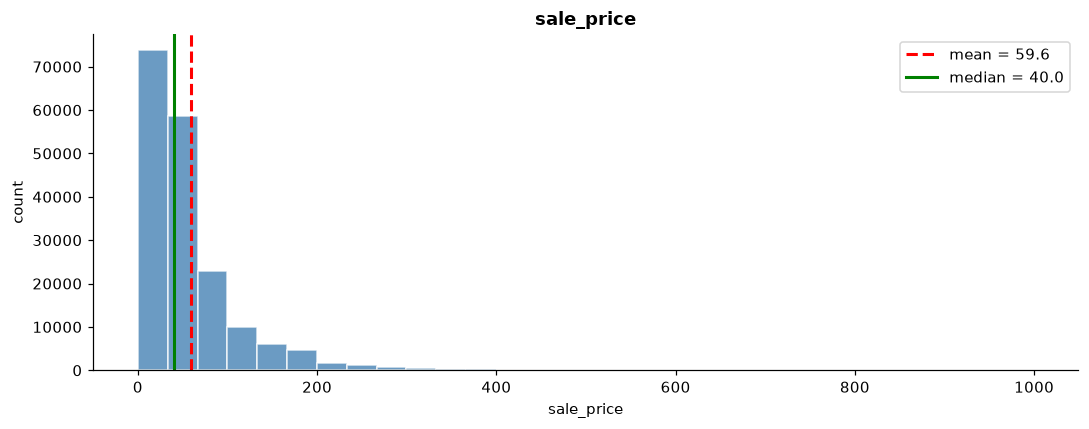

In [16]:
plot_histogram(df, "sale_price")

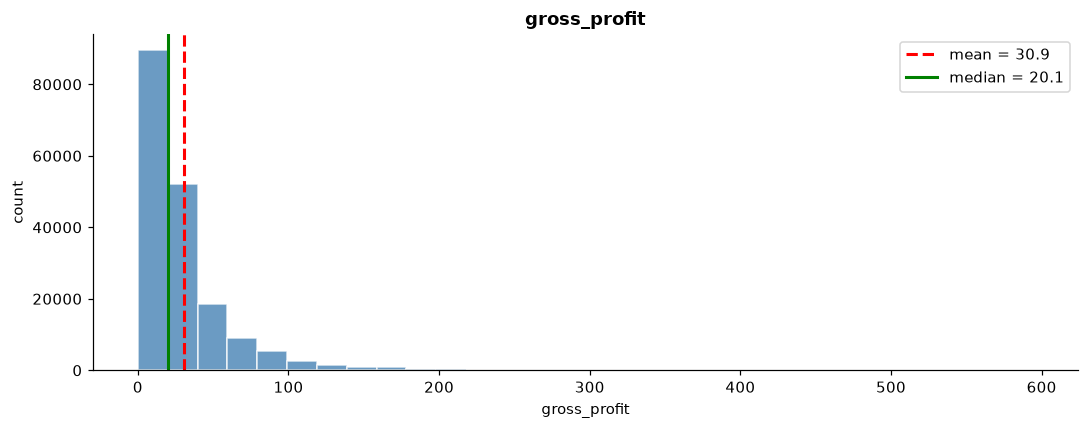

In [17]:
plot_histogram(df, "gross_profit")

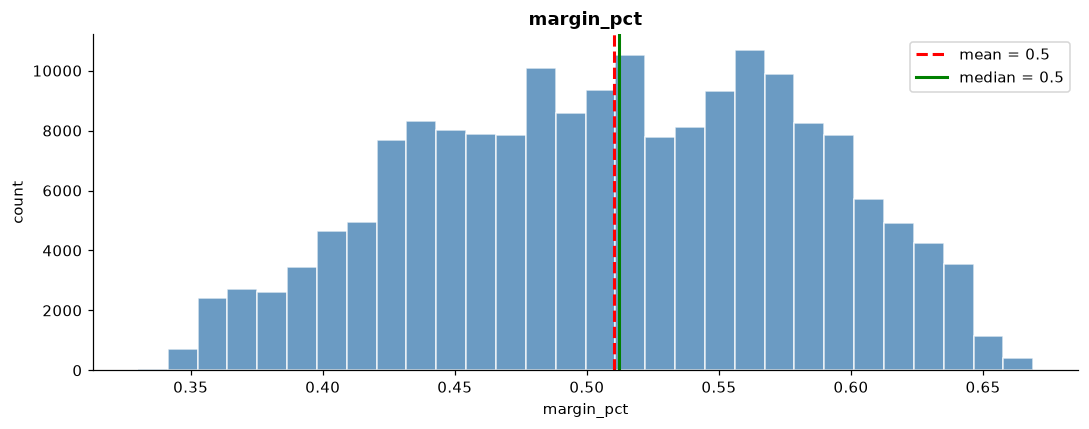

In [18]:
plot_histogram(df, "margin_pct")

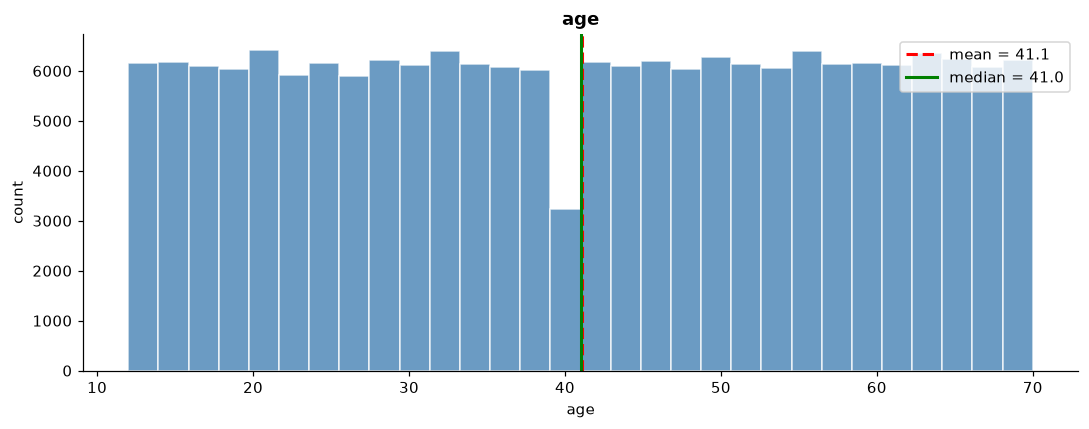

In [19]:
plot_histogram(df, "age")

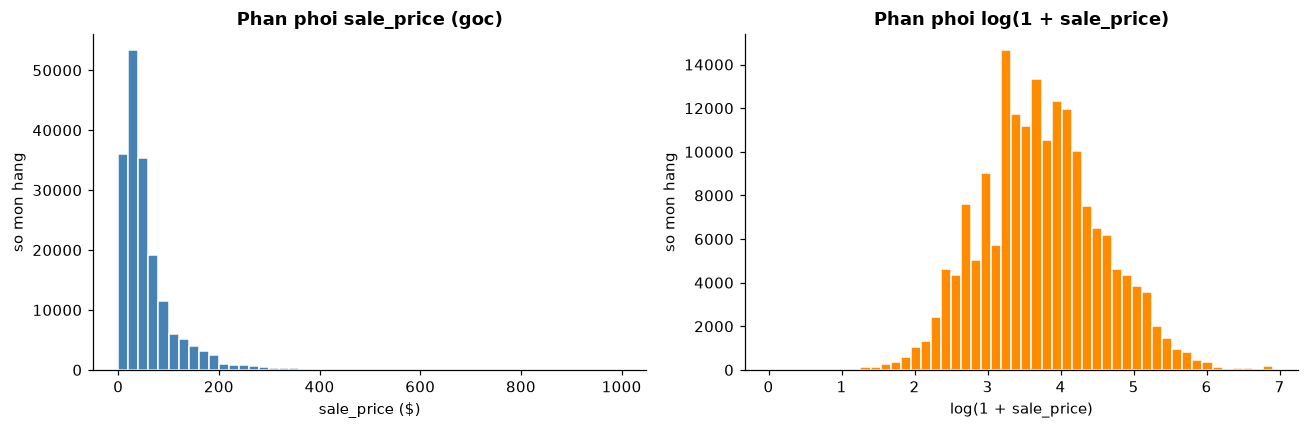

In [20]:
# sale_price lech phai -> xem tren thang log de thay ro hinh dang
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["sale_price"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Phan phoi sale_price (goc)")
axes[0].set_xlabel("sale_price ($)")
axes[0].set_ylabel("so mon hang")

axes[1].hist(np.log1p(df["sale_price"]), bins=50, color="darkorange", edgecolor="white")
axes[1].set_title("Phan phoi log(1 + sale_price)")
axes[1].set_xlabel("log(1 + sale_price)")
axes[1].set_ylabel("so mon hang")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_01_sale_price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Xu huong theo thoi gian

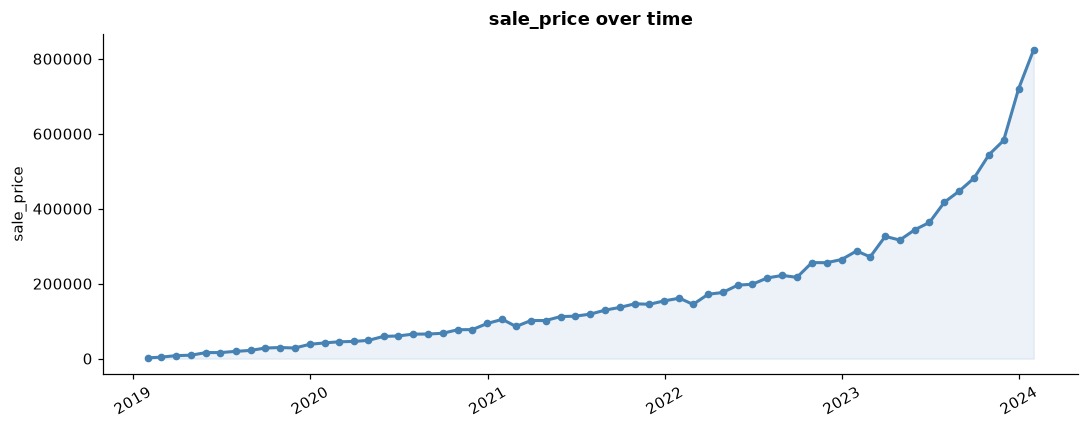

In [21]:
plot_line(df, "created_at", "sale_price", freq="ME")

In [22]:
# Doanh thu thuc thu: bo don Cancelled va Returned
df_net = df[~df["status"].isin(["Cancelled", "Returned"])]

year_summary = df_net.groupby("year").agg(
    net_revenue = ("sale_price", "sum"),
    gross_profit = ("gross_profit", "sum"),
    total_orders = ("order_id", "nunique"),
    total_customers = ("user_id", "nunique")
)
year_summary["revenue_growth"] = year_summary["net_revenue"].pct_change()
year_summary.round(2)

,net_revenue,gross_profit,total_orders,total_customers,revenue_growth
year,,,,,
2019,1.651741e+05,8.547754e+04,1931,1845,NaN
2020,5.621470e+05,2.920972e+05,6515,6019,2.40
2021,1.090479e+06,5.659541e+05,12558,11384,0.94
2022,1.867970e+06,9.682604e+05,21967,19408,0.71
2023,3.821823e+06,1.983649e+06,44279,35475,1.05
2024,6.197441e+05,3.219393e+05,7056,5773,-0.84


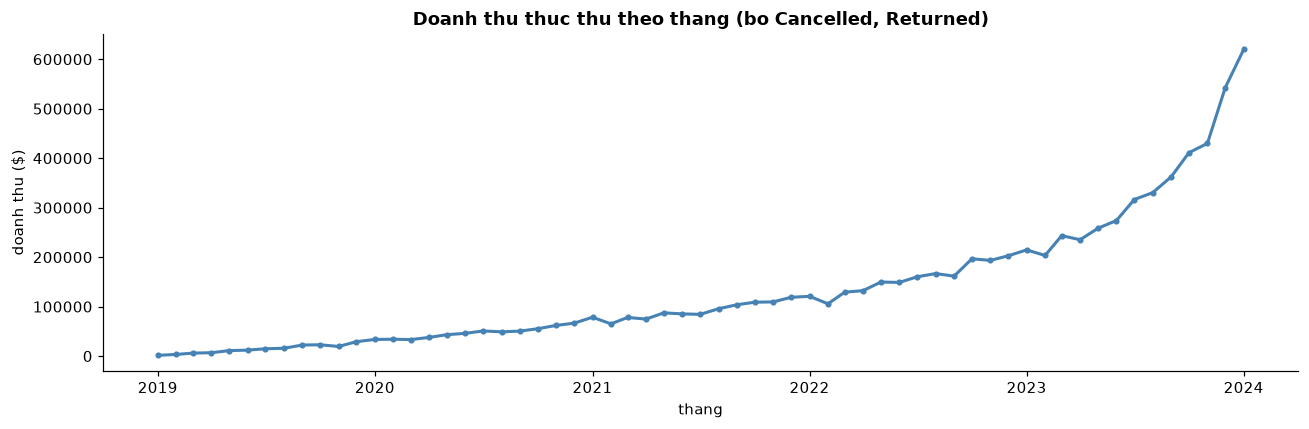

In [23]:
monthly = df_net.groupby("year_month")["sale_price"].sum()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index.to_timestamp(), monthly.values, marker="o", ms=3, lw=2, color="steelblue")
ax.set_title("Doanh thu thuc thu theo thang (bo Cancelled, Returned)")
ax.set_xlabel("thang")
ax.set_ylabel("doanh thu ($)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_02_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhan xet:** doanh thu tang deu qua tung nam (xem cot `revenue_growth`). Nam 2024 chi co du lieu den thang 1 nen **khong so sanh 2024 voi cac nam truoc**.

## Boxplot

c:\cache\CyperSoft\CyperSoft_Final Project\src\utils\visual.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=cat_col, y=num_col,


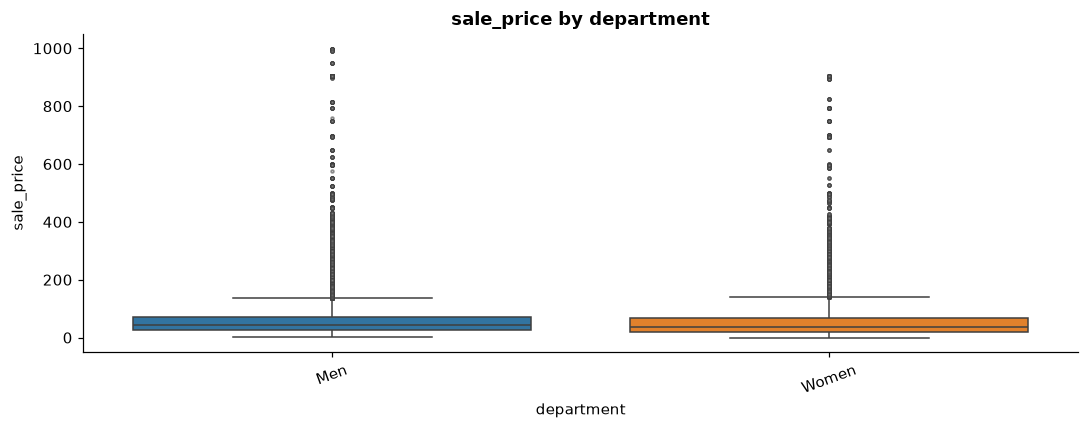

In [24]:
plot_boxplot(df, "sale_price", "department")

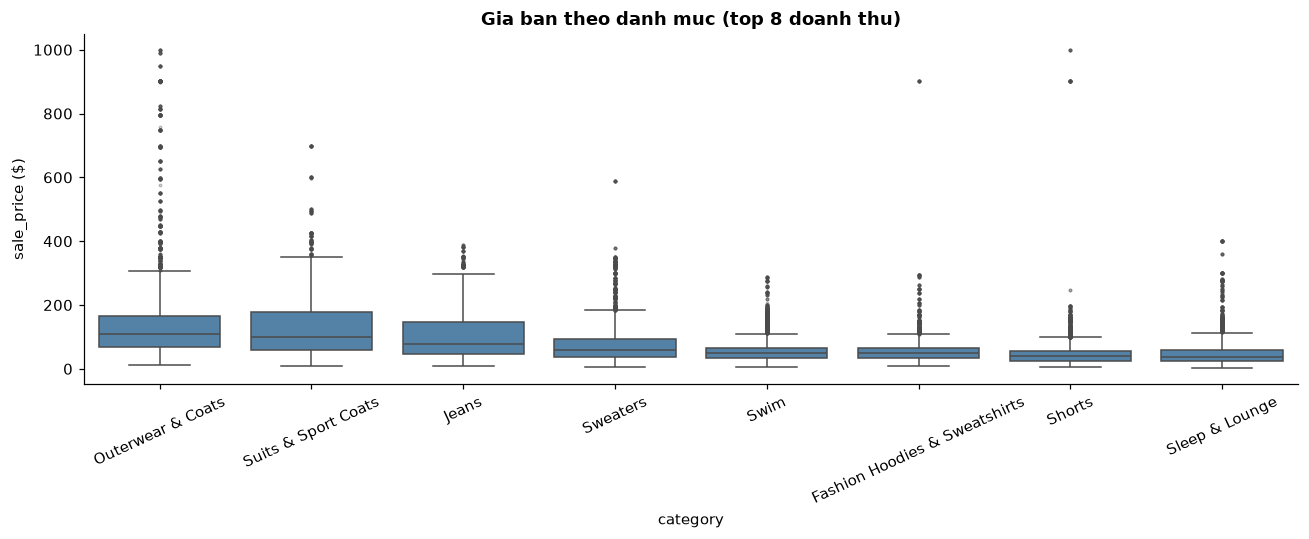

In [25]:
# Boxplot gia ban theo 8 danh muc co doanh thu cao nhat
top_cat = df.groupby("category", observed=True)["sale_price"].sum().nlargest(8).index
df_top = df[df["category"].isin(top_cat)].copy()
df_top["category"] = df_top["category"].astype(str)

fig, ax = plt.subplots(figsize=(12, 5))
order = df_top.groupby("category")["sale_price"].median().sort_values(ascending=False).index
sns.boxplot(data=df_top, x="category", y="sale_price", order=order, color="steelblue",
            flierprops={"marker": ".", "markersize": 3, "alpha": 0.4}, ax=ax)
ax.set_title("Gia ban theo danh muc (top 8 doanh thu)")
ax.set_xlabel("category")
ax.set_ylabel("sale_price ($)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_03_boxplot_price_category.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. OUTLIER

## Detect outlier

In [26]:
col = "sale_price"
data_outliers = df[col].dropna()

q1 = data_outliers.quantile(0.25)
q3 = data_outliers.quantile(0.75)
IQR = q3 - q1
lower = q1 - IQR * 1.5 # Gan cuc tieu
upper = q3 + IQR * 1.5 # Gan cuc dai

print(f"Q1 and Q3 is: {q1} and {q3}")
print(f"lower = {lower:.2f}, upper = {upper:.2f}")

Q1 and Q3 is: 24.5 and 69.94999694824219
lower = -43.67, upper = 138.12


In [27]:
detect_outliers(data_outliers)

{'lower': np.float64(-43.67499542236328),
 'upper': np.float64(138.12499237060547),
 'mask': 0         False
 1         False
 2         False
 3         False
 4         False
           ...  
 181754    False
 181755    False
 181756    False
 181757    False
 181758    False
 Name: sale_price, Length: 181759, dtype: bool,
 'n_out': 15444,
 'pct_out': np.float64(8.5)}

In [28]:
outlier_summary(df, ["sale_price", "gross_profit", "margin_pct"])

column                      lower      upper    n_out    pct
------------------------------------------------------------
sale_price                  -43.7      138.1   15,444   8.5%
gross_profit                -24.5       72.1   15,693   8.6%
margin_pct                    0.3        0.7        0   0.0%


c:\cache\CyperSoft\CyperSoft_Final Project\src\utils\outlier.py:61: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\cache\CyperSoft\CyperSoft_Final Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


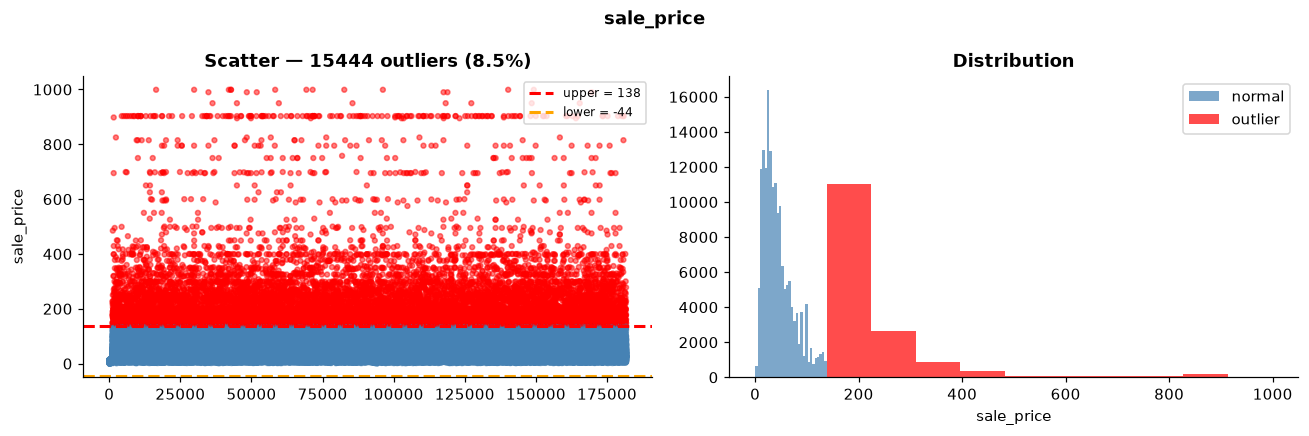

In [29]:
plot_outlier(df, "sale_price")

In [30]:
# Outlier anh huong the nao den ket qua kinh doanh?
is_out = df["sale_price"] > upper
df_net_out = df_net["sale_price"] > upper

print(f"Ty le mon hang outlier       : {is_out.mean():.1%}")
print(f"Ty trong doanh thu thuc thu  : {df_net.loc[df_net_out, 'sale_price'].sum() / df_net['sale_price'].sum():.1%}")
print(f"Ty trong loi nhuan thuc thu  : {df_net.loc[df_net_out, 'gross_profit'].sum() / df_net['gross_profit'].sum():.1%}")

Ty le mon hang outlier       : 8.5%
Ty trong doanh thu thuc thu  : 31.6%
Ty trong loi nhuan thuc thu  : 32.6%


In [31]:
# Outlier tap trung o danh muc nao
df.loc[is_out, "category"].value_counts(normalize=True).head(8).round(3)

category
Jeans                  0.216
Outerwear & Coats      0.205
Suits & Sport Coats    0.124
Sweaters               0.083
Dresses                0.057
Blazers & Jackets      0.048
Accessories            0.038
Swim                   0.033
Name: proportion, dtype: float64

## Xu li outlier

**Quyet dinh: giu nguyen, khong xoa, khong capping.**
- Outlier o day la mon hang gia cao co that (ao khoac, vest, jeans...), khong phai loi nhap lieu.
- Nhom nay chi chiem mot phan nho so mon hang nhung dong gop ty trong doanh thu va loi nhuan lon (so lieu o cell tren). Xoa hoac capping se lam **sai doanh thu**.
- Neu can phan tich rieng thi dung cot co `is_price_outlier`.

In [32]:
df["is_price_outlier"] = (df["sale_price"] > upper).astype(int)
df["is_price_outlier"].value_counts()

is_price_outlier
0    166315
1     15444
Name: count, dtype: int64

# 3. PHAN TICH DA BIEN & TUONG QUAN

## Muc mon hang

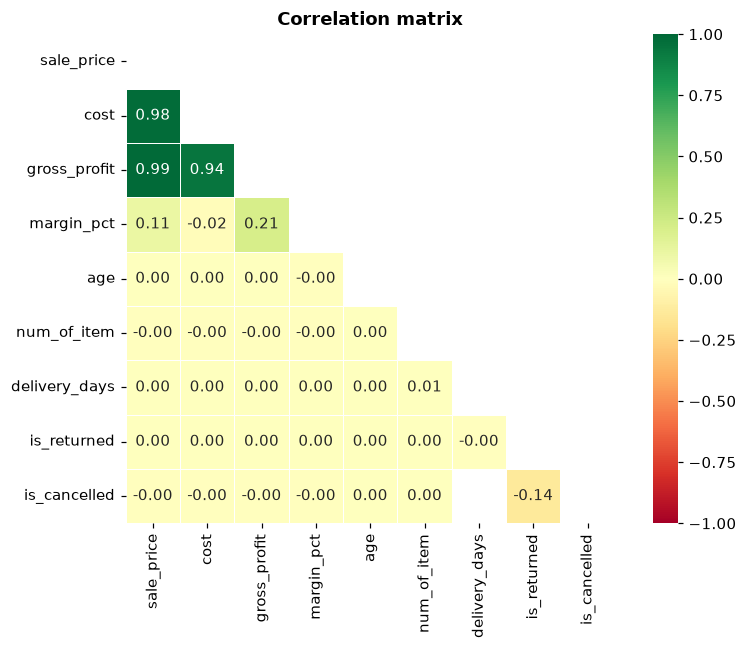

In [33]:
cols = ["sale_price", "cost", "gross_profit", "margin_pct", "age", "num_of_item",
        "delivery_days", "is_returned", "is_cancelled"]

plot_heatmap_corr(df, cols)

**Nhan xet:** `sale_price`, `cost`, `gross_profit` tuong quan rat cao voi nhau (vi loi nhuan = gia - von). Cac bien con lai, nhat la `is_returned` va `is_cancelled`, gan nhu **khong tuong quan** voi gia, tuoi, so mon trong don hay thoi gian giao.

## Gia ban tac dong the nao den ty le huy / tra hang

In [34]:
df["price_group"] = pd.qcut(df["sale_price"], 5, labels=["rat re", "re", "trung binh", "cao", "rat cao"])

price_effect = df.groupby("price_group", observed=True).agg(
    so_mon = ("order_item_id", "count"),
    cancel_rate = ("is_cancelled", "mean"),
    return_rate = ("is_returned", "mean"),
    margin_pct = ("margin_pct", "mean")
).round(4)
price_effect

,so_mon,cancel_rate,return_rate,margin_pct
price_group,,,,
rat re,36961,0.1506,0.1000,0.5086
re,35763,0.1514,0.1000,0.5069
trung binh,36740,0.1459,0.0980,0.5039
cao,35948,0.1496,0.1000,0.5055
rat cao,36347,0.1478,0.1034,0.5272


## Thoi gian van chuyen tac dong the nao den ty le tra hang

In [35]:
# chi xet mon da giao (delivered hoac returned)
df_deli = df[df["delivered_at"].notnull()].copy()
df_deli["delivery_group"] = pd.cut(df_deli["delivery_days"], bins=[0, 1, 2, 3, 4, 5],
                                   labels=["<1 ngay", "1-2 ngay", "2-3 ngay", "3-4 ngay", "4-5 ngay"],
                                   include_lowest=True)

delivery_effect = df_deli.groupby("delivery_group", observed=True).agg(
    so_mon = ("order_item_id", "count"),
    return_rate = ("is_returned", "mean")
).round(4)
delivery_effect

,so_mon,return_rate
delivery_group,,
<1 ngay,12703,0.2888
1-2 ngay,12509,0.2889
2-3 ngay,12961,0.2840
3-4 ngay,12572,0.2803
4-5 ngay,13096,0.2860


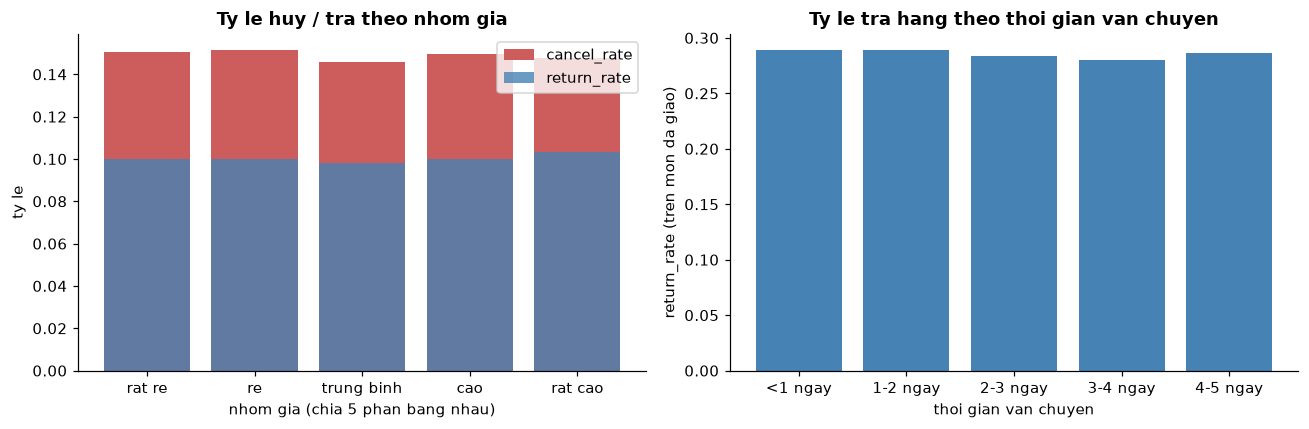

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(price_effect.index.astype(str), price_effect["cancel_rate"], color="indianred", label="cancel_rate")
axes[0].bar(price_effect.index.astype(str), price_effect["return_rate"], color="steelblue", label="return_rate", alpha=0.8)
axes[0].set_title("Ty le huy / tra theo nhom gia")
axes[0].set_xlabel("nhom gia (chia 5 phan bang nhau)")
axes[0].set_ylabel("ty le")
axes[0].legend()

axes[1].bar(delivery_effect.index.astype(str), delivery_effect["return_rate"], color="steelblue")
axes[1].set_title("Ty le tra hang theo thoi gian van chuyen")
axes[1].set_xlabel("thoi gian van chuyen")
axes[1].set_ylabel("return_rate (tren mon da giao)")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_04_price_delivery_vs_cancel_return.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhan xet:** ty le huy va ty le tra hang gan nhu **bang nhau o moi nhom gia va moi muc thoi gian van chuyen**.
-> Gia va toc do giao **khong phai** nguyen nhan chinh gay huy / tra hang. Can them du lieu ly do huy / tra (vd: sai size, giao cham, doi y) de tim nguyen nhan.

## Danh muc: doanh thu vs bien loi nhuan

In [37]:
category_overall = df_net.groupby("category", observed=True).agg(
    net_revenue = ("sale_price", "sum"),
    gross_profit = ("gross_profit", "sum"),
    so_mon = ("order_item_id", "count")
)
category_overall["margin_pct"] = category_overall["gross_profit"] / category_overall["net_revenue"]
category_overall["revenue_share"] = category_overall["net_revenue"] / category_overall["net_revenue"].sum()
category_overall = category_overall.sort_values("net_revenue", ascending=False)
category_overall.round(3)

,net_revenue,gross_profit,so_mon,margin_pct,revenue_share
category,,,,,
Outerwear & Coats,983391.875000,545698.937500,6725,0.555,0.121
Jeans,941800.625000,437515.218750,9518,0.465,0.116
Sweaters,637020.437500,330424.031250,8470,0.519,0.078
Suits & Sport Coats,497929.812500,297924.562500,3899,0.598,0.061
Fashion Hoodies & Sweatshirts,488461.312500,234634.390625,8919,0.480,0.060
Swim,483074.125000,236333.328125,8564,0.489,0.059
Sleep & Lounge,408091.281250,209958.515625,8366,0.514,0.050
Shorts,378403.500000,188941.312500,8249,0.499,0.047
Tops & Tees,369301.625000,162508.468750,8965,0.440,0.045


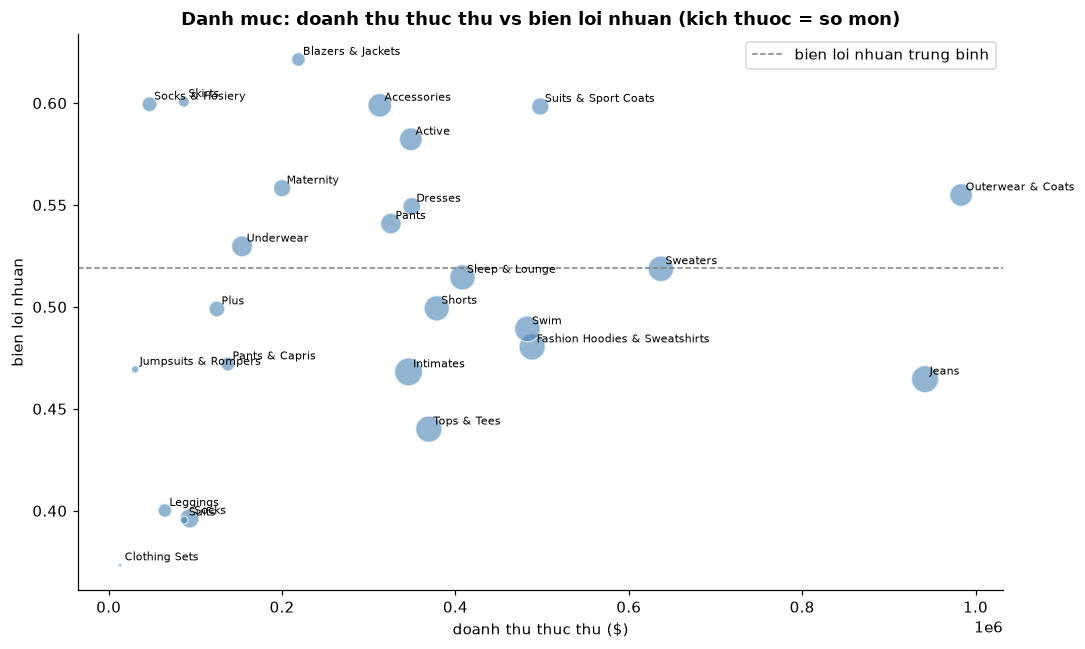

In [38]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(category_overall["net_revenue"], category_overall["margin_pct"],
           s=category_overall["so_mon"] / 30, color="steelblue", alpha=0.6, edgecolor="white")
for name, row in category_overall.iterrows():
    ax.annotate(name, (row["net_revenue"], row["margin_pct"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(category_overall["gross_profit"].sum() / category_overall["net_revenue"].sum(),
           color="gray", ls="--", lw=1, label="bien loi nhuan trung binh")
ax.set_title("Danh muc: doanh thu thuc thu vs bien loi nhuan (kich thuoc = so mon)")
ax.set_xlabel("doanh thu thuc thu ($)")
ax.set_ylabel("bien loi nhuan")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_05_category_revenue_vs_margin.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhan xet:** danh muc doanh thu cao chua chac loi nhuan cao. Xem bang tren: so sanh `margin_pct` cua cac danh muc top doanh thu voi muc trung binh (duong net dut) de chon danh muc nen day manh / can xem lai gia von.

## Muc khach hang: tan suat mua lai

In [39]:
query_user = """
select o.order_id,
       o.user_id,
       o.status,
       o.created_at,
       o.num_of_item,
       u.age,
       u.gender,
       u.traffic_source
from orders o
join users u on o.user_id = u.id
"""

df_orders = load_main_dataset(query_user, engine)
df_orders.head()

,order_id,user_id,status,created_at,num_of_item,age,gender,traffic_source
0,300,250,Cancelled,2023-10-19 01:18:00,2,30,F,Search
1,816,655,Cancelled,2024-01-08 11:47:00,1,55,F,Search
2,1087,873,Cancelled,2023-01-19 17:23:00,4,18,F,Organic
3,1450,1160,Cancelled,2022-02-13 09:25:00,1,34,F,Organic
4,1830,1477,Cancelled,2023-12-21 15:14:00,1,29,F,Search


In [40]:
user_net_revenue = df_net.groupby("user_id", observed=True)["sale_price"].sum()

df_user = df_orders.groupby("user_id").agg(
    total_orders = ("order_id", "count"),
    avg_items = ("num_of_item", "mean"),
    cancel_rate = ("status", lambda s: (s == "Cancelled").mean()),
    return_rate = ("status", lambda s: (s == "Returned").mean()),
    age = ("age", "first"),
    traffic_source = ("traffic_source", "first")
)
df_user["net_revenue"] = user_net_revenue.reindex(df_user.index).fillna(0)
df_user["is_repeat"] = (df_user["total_orders"] > 1).astype(int)

print(f"So khach da mua: {len(df_user)}")
print(f"Ty le khach mua lai (>1 don): {df_user['is_repeat'].mean():.1%}")
df_user["total_orders"].value_counts().sort_index()

So khach da mua: 80044
Ty le khach mua lai (>1 don): 37.7%


total_orders
1    49832
2    20231
3     4992
4     4989
Name: count, dtype: int64

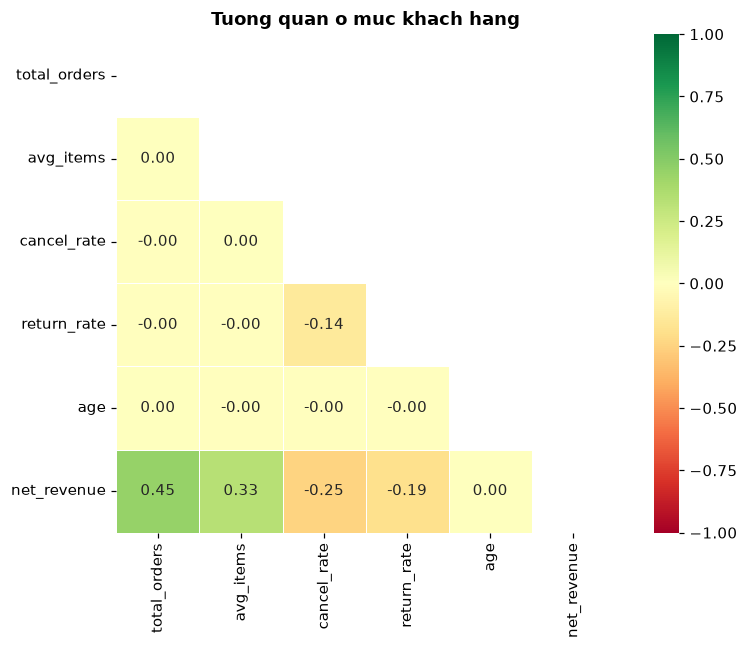

In [41]:
plot_heatmap_corr(df_user, ["total_orders", "avg_items", "cancel_rate", "return_rate", "age", "net_revenue"],
                  title="Tuong quan o muc khach hang")

In [42]:
# Nguon traffic co anh huong den viec quay lai mua khong
repeat_by_source = df_user.groupby("traffic_source").agg(
    so_khach = ("is_repeat", "size"),
    repeat_rate = ("is_repeat", "mean"),
    avg_net_revenue = ("net_revenue", "mean")
).sort_values("so_khach", ascending=False).round(3)
repeat_by_source

,so_khach,repeat_rate,avg_net_revenue
traffic_source,,,
Search,56070,0.378,101.602997
Organic,12117,0.377,100.931000
Facebook,4676,0.370,100.871002
Email,3930,0.380,102.920998
Display,3251,0.374,101.907997


In [43]:
# Trai nghiem don dau tien (bi huy / bi tra) co lam khach khong quay lai khong
first_order = df_orders.sort_values("created_at").groupby("user_id").first()
first_order["is_repeat"] = df_user["is_repeat"]
first_order.groupby("status")["is_repeat"].agg(["count", "mean"]).round(4)

,count,mean
status,,
Cancelled,11910,0.3768
Complete,20118,0.3744
Processing,16076,0.3825
Returned,8003,0.3716
Shipped,23937,0.3788


**Nhan xet:**
- Doanh thu cua khach tang theo so don (`total_orders`) va so mon moi don (`avg_items`) -> muon tang doanh thu tren moi khach thi tap trung vao **mua lai** va **ban kem (cross-sell)**.
- Ty le mua lai gan nhu nhu nhau giua cac nguon traffic va giua khach co don dau bi huy / bi tra hay khong.

# 4. INSIGHT PHU: HANH VI TRUY CAP WEB (POWER BI KHONG CO)

Bang `events` (2,4 trieu dong) khong dua vao Power BI. Gom bang SQL truoc roi moi doc vao pandas.

In [44]:
query_funnel = """
select traffic_source,
       event_type,
       count(distinct session_id) as total_sessions
from events
group by traffic_source, event_type
"""

df_funnel = load_main_dataset(query_funnel, engine)
funnel = df_funnel.pivot(index="traffic_source", columns="event_type", values="total_sessions")
funnel["cart_rate"] = funnel["cart"] / funnel["product"]
funnel["purchase_rate"] = funnel["purchase"] / funnel["product"]
funnel["cart_to_purchase"] = funnel["purchase"] / funnel["cart"]
funnel.round(3)

event_type,cancel,cart,department,home,product,purchase,cart_rate,purchase_rate,cart_to_purchase
traffic_source,,,,,,,,,
Adwords,37795,130001,129606,26350,205010,54542,0.634,0.266,0.420
Email,56170,193988,194047,39495,306313,81706,0.633,0.267,0.421
Facebook,12669,43372,42991,8794,67933,18305,0.638,0.269,0.422
Organic,6284,21603,21711,4379,34301,9124,0.630,0.266,0.422
YouTube,12650,43182,43120,8694,68202,18082,0.633,0.265,0.419


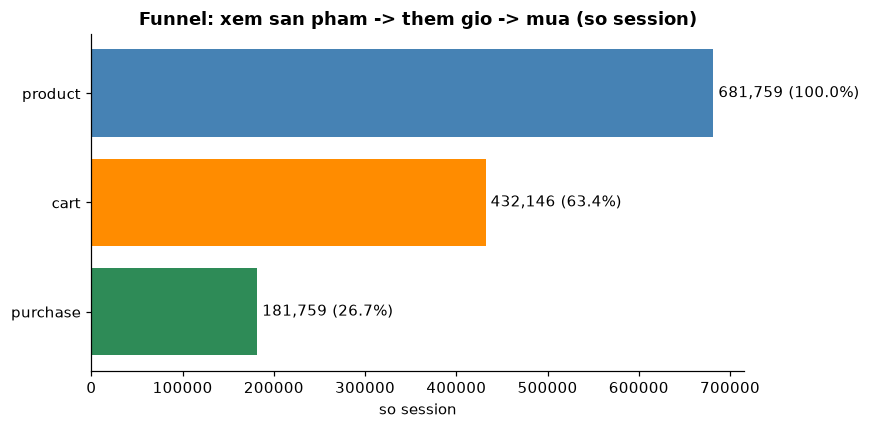

In [45]:
steps = ["product", "cart", "purchase"]
total = funnel[steps].sum()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(steps[::-1], total[steps[::-1]].values, color=["seagreen", "darkorange", "steelblue"])
for i, s in enumerate(steps[::-1]):
    ax.text(total[s], i, f" {total[s]:,.0f} ({total[s] / total['product']:.1%})", va="center")
ax.set_title("Funnel: xem san pham -> them gio -> mua (so session)")
ax.set_xlabel("so session")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_06_funnel.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhan xet:** buoc roi bo lon nhat la tu **gio hang -> mua** (xem `cart_to_purchase`). Ty le chuyen doi gan nhu giong nhau giua cac nguon traffic -> van de nam o buoc thanh toan, khong nam o kenh quang cao.

# TONG KET INSIGHT

Moi insight: **Phat hien -> Bang chung (cell / bieu do) -> De xuat**. So lieu cu the xem trong output cac cell tuong ung va file `docs/eda_explanation.md`.

1. **Gia ban lech phai manh** (muc Thong ke, `eda_01`): bao cao gia tri dien hinh bang median, khong dung mean.
2. **Doanh thu tang deu theo nam** (`eda_02`, bang `year_summary`): 2024 chi co thang 1, khong so sanh.
3. **Outlier gia cao la don that, dong gop lon vao doanh thu** (muc Outlier): giu lai, khong xoa.
4. **Huy / tra hang khong phu thuoc gia hay thoi gian giao** (`eda_04`): can thu thap ly do huy / tra.
5. **Danh muc doanh thu cao chua chac bien loi nhuan cao** (`eda_05`): xem lai gia von nhom doanh thu cao - bien thap.
6. **Doanh thu moi khach den tu so don va so mon** (heatmap muc khach hang): day manh mua lai va ban kem.
7. **Roi bo lon nhat o buoc gio hang -> mua** (`eda_06`): toi uu thanh toan, nhac gio hang bo do.
8. **Chat luong du lieu**: mot phan lon mon hang co `shipped_at` som hon `created_at` -> khong dung de tinh thoi gian xu ly don.